In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [2]:
df = pd.read_csv("data.csv")

In [3]:
df.columns = df.columns.str.strip()

In [4]:
df.shape
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Bankrupt?                                                6819 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2   ROA(A) before interest and % after tax                   6819 non-null   float64
 3   ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4   Operating Gross Margin                                   6819 non-null   float64
 5   Realized Sales Gross Margin                              6819 non-null   float64
 6   Operating Profit Rate                                    6819 non-null   float64
 7   Pre-tax net Interest Rate                                6819 non-null   float64
 8   After-tax net Interest Rate            

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


In [5]:
df.isnull().sum().sum()
df.duplicated().sum()


np.int64(0)

In [6]:
df["Bankrupt?"].value_counts()
df["Bankrupt?"].value_counts(normalize=True) * 100


Bankrupt?
0    96.77372
1     3.22628
Name: proportion, dtype: float64

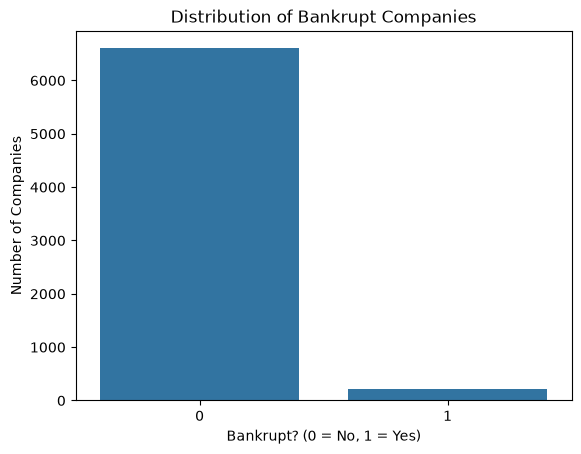

In [7]:
sns.countplot(x="Bankrupt?", data=df)
plt.title("Distribution of Bankrupt Companies")
plt.xlabel("Bankrupt? (0 = No, 1 = Yes)")
plt.ylabel("Number of Companies")
plt.show()

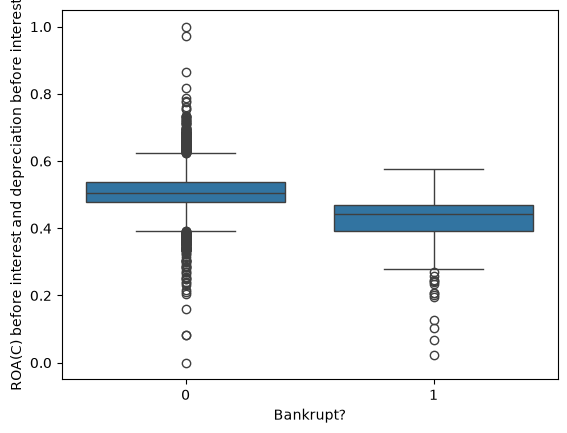

In [8]:
roa_c = "ROA(C) before interest and depreciation before interest"
df.groupby("Bankrupt?")[roa_c].mean()

sns.boxplot(x="Bankrupt?", y=roa_c, data=df)
plt.show()


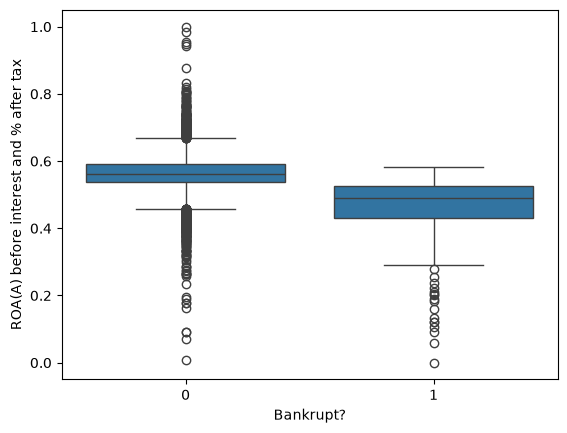

In [9]:
roa_a = "ROA(A) before interest and % after tax"
df.groupby("Bankrupt?")[roa_a].mean()

sns.boxplot(x="Bankrupt?", y=roa_a, data=df)
plt.show()


In [10]:
spearman_corr = df.corr(method="spearman", numeric_only=True)["Bankrupt?"]
spearman_corr = spearman_corr.drop("Bankrupt?")

In [11]:
top10_signed = spearman_corr.loc[
    spearman_corr.abs().sort_values(ascending=False).head(10).index
]


In [12]:
top5_features = top10_signed.index[:5].tolist()

In [13]:
mean_top5 = df.groupby("Bankrupt?")[top5_features].mean().T
median_top5 = df.groupby("Bankrupt?")[top5_features].median().T


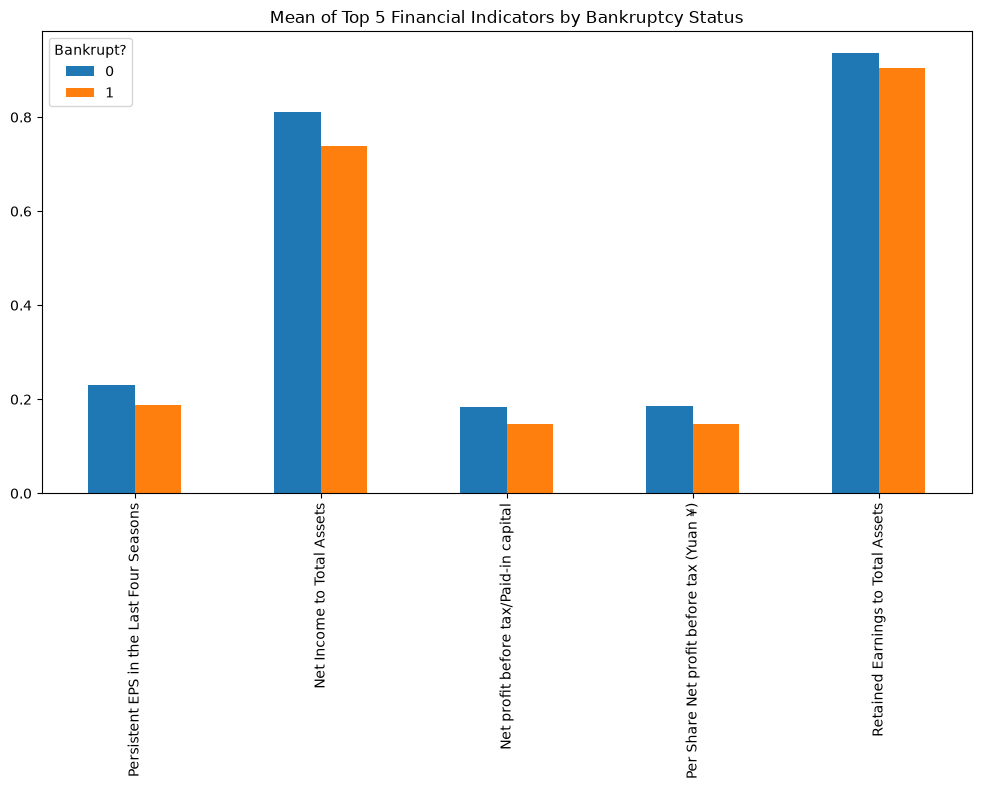

In [14]:
mean_top5.plot(kind="bar", figsize=(12, 6))
plt.title("Mean of Top 5 Financial Indicators by Bankruptcy Status")
plt.show()
